In [1]:
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
image_path = "test.png" 

In [3]:
if not Path(image_path).exists():
    raise FileNotFoundError(f"Image not found: {image_path}")

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

In [5]:

dft = cv2.dft(np.float32(image), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(
    cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1
)

rows, cols = image.shape
crow, ccol = rows // 2, cols // 2

radius = min(rows, cols) // 8
y, x = np.ogrid[:rows, :cols]
distance = np.sqrt((x - ccol) ** 2 + (y - crow) ** 2)

low_pass_mask = np.zeros((rows, cols, 2), np.float32)
low_pass_mask[distance <= radius] = 1

high_pass_mask = np.ones((rows, cols, 2), np.float32)
high_pass_mask[distance <= radius] = 0


low_pass_dft = dft_shift * low_pass_mask
high_pass_dft = dft_shift * high_pass_mask


low_pass_image = cv2.idft(np.fft.ifftshift(low_pass_dft))
low_pass_image = cv2.magnitude(
    low_pass_image[:, :, 0], low_pass_image[:, :, 1]
)

high_pass_image = cv2.idft(np.fft.ifftshift(high_pass_dft))
high_pass_image = cv2.magnitude(
    high_pass_image[:, :, 0], high_pass_image[:, :, 1]
)


low_pass_image = cv2.normalize(low_pass_image, None, 0, 255, cv2.NORM_MINMAX)
high_pass_image = cv2.normalize(high_pass_image, None, 0, 255, cv2.NORM_MINMAX)


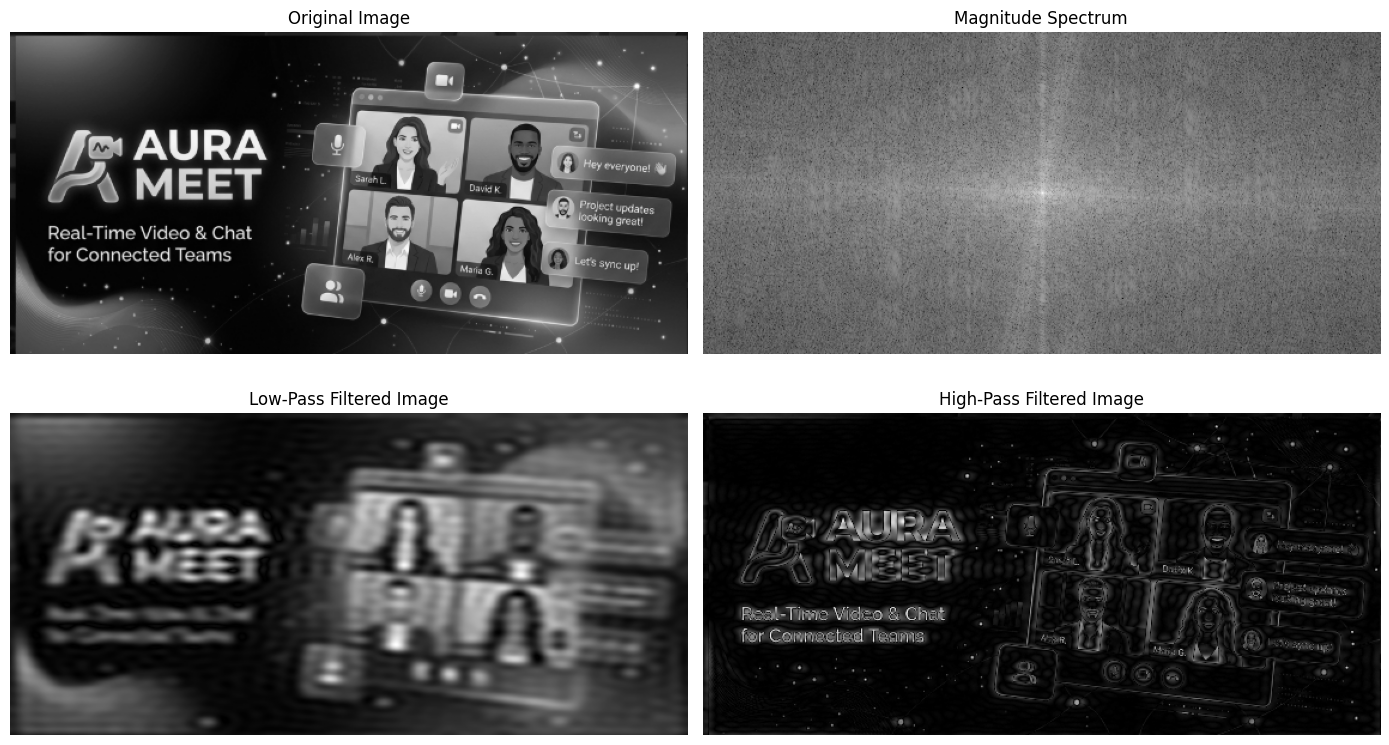

In [6]:

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Magnitude Spectrum")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(low_pass_image, cmap="gray")
plt.title("Low-Pass Filtered Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(high_pass_image, cmap="gray")
plt.title("High-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## Answers

### 1. What is the Fourier Transform?

The Fourier Transform converts an image from the spatial domain into the frequency domain. It represents the image as a combination of different spatial frequencies.

It is important because it helps analyze image details, smooth regions, edges, noise, and periodic patterns.

### 2. Spatial Domain vs Frequency Domain

- **Spatial domain:** Operations are performed directly on image pixels.
- **Frequency domain:** The image is represented using frequency components, and operations are performed on its Fourier spectrum.

Spatial-domain methods are generally intuitive, while frequency-domain methods are useful for filtering and analyzing image structures.

### 3. Significance of the DFT

The Discrete Fourier Transform (DFT) converts a digital image into its discrete frequency representation. It allows computers to analyze and modify image frequencies and is commonly implemented efficiently using the Fast Fourier Transform (FFT).

### 4. Purpose of Centering the Zero-Frequency Component

The zero-frequency component represents the average image intensity. Shifting it to the center makes the frequency spectrum easier to visualize and simplifies the design of circular frequency filters.

### 5. Low-Pass and High-Pass Filters

- **Low-pass filter:** Preserves low frequencies and removes high frequencies. It smooths images, reduces noise, and blurs sharp details.
- **High-pass filter:** Preserves high frequencies and removes low frequencies. It enhances edges, boundaries, and fine details.

### 6. Role of the IDFT

The Inverse Discrete Fourier Transform converts a modified frequency-domain image back into the spatial domain. It reconstructs the filtered image so that it can be displayed and analyzed.

### 7. Why Use Frequency-Domain Filtering?

Frequency-domain filtering provides direct control over different image frequencies. It is especially effective for removing periodic noise, smoothing images, enhancing edges, and performing large-kernel filtering.

### 8. Four Real-World Applications

1. Medical image enhancement and analysis  
2. Satellite and remote-sensing image processing  
3. Industrial defect detection  
4. Astronomical image analysis and noise reduction  

### 9. Frequency-Domain vs Spatial-Domain Filtering

Spatial filtering is simpler and effective for small kernels and local operations. Frequency-domain filtering can be more computationally efficient for large kernels because convolution becomes multiplication after the Fourier Transform.

However, frequency-domain filtering requires forward and inverse transforms, making spatial filtering preferable for simple local tasks.

### 10. Effect on Restoration and Feature Extraction

Frequency-domain filtering can suppress known noise frequencies and reduce blur-related distortions. High-pass filtering also emphasizes edges and textures, improving feature extraction for object recognition, segmentation, and shape analysis.

## Observations

The low-pass filtered image appears smoother because high-frequency components such as noise and sharp edges are reduced. The high-pass filtered image emphasizes edges and fine details. The magnitude spectrum shows how image intensity is distributed across different frequencies.

Frequency-domain filtering is advantageous because it provides precise frequency control, efficiently handles large filtering operations, and is effective for enhancement, restoration, and noise removal.